# 04 · Return on capex
**Where to Invest: Microsoft Growth Investment Analysis**

Goal: decide which datacenter regions earn their cost of capital, and where the next capex dollar should go.
For each of the 34 cloud regions: capex (owned and leased), capacity added, utilisation, operating margin after
depreciation, return on capex, payback and NPV at a 9% hurdle rate, with sensitivity at 7% and 11%.

Tools: SQL (DuckDB) views built in `03_profitability.ipynb`; Python (pandas) to read them; matplotlib for the charts.

> **Synthetic data, calibrated to Microsoft's published results.** Generated by `data/generate.py`: totals by
> segment and quarter are close to Microsoft's reported figures; every record underneath them is invented.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

# The database and its views were built in 03_profitability.ipynb; here we only read them
con = duckdb.connect("data/finance.duckdb", read_only=True)


def billions(value):
    """Format USD as $12.3B."""
    return f"${value / 1_000_000_000:,.1f}B"


params = con.sql("SELECT * FROM v_params").df()
HURDLE = params["hurdle_rate"].iloc[0]
params

,data_start,base_end,ttm_start,data_end,hurdle_rate,hurdle_rate_low,hurdle_rate_high,life_years_build,life_years_fleet,life_years_network,target_utilization
0,2024-01-01,2024-12-01,2025-10-01,2026-09-01,0.09,0.07,0.11,15,6,10,0.9


## 1. Capex and free cash flow

Capex here is **capex including finance leases**, as Microsoft reports it. Under IFRS 16 / ASC 842 a finance lease
puts a right-of-use asset and a lease liability on the balance sheet when the datacenter is handed over, so it is
an investment decision like a purchase. The cash, however, is paid over the lease term (principal in financing
cash flows), so **free cash flow as Microsoft reports it excludes finance leases**. Both views are shown.

Free cash flow (simplified) = operating income + depreciation − capex; working capital and tax are ignored.

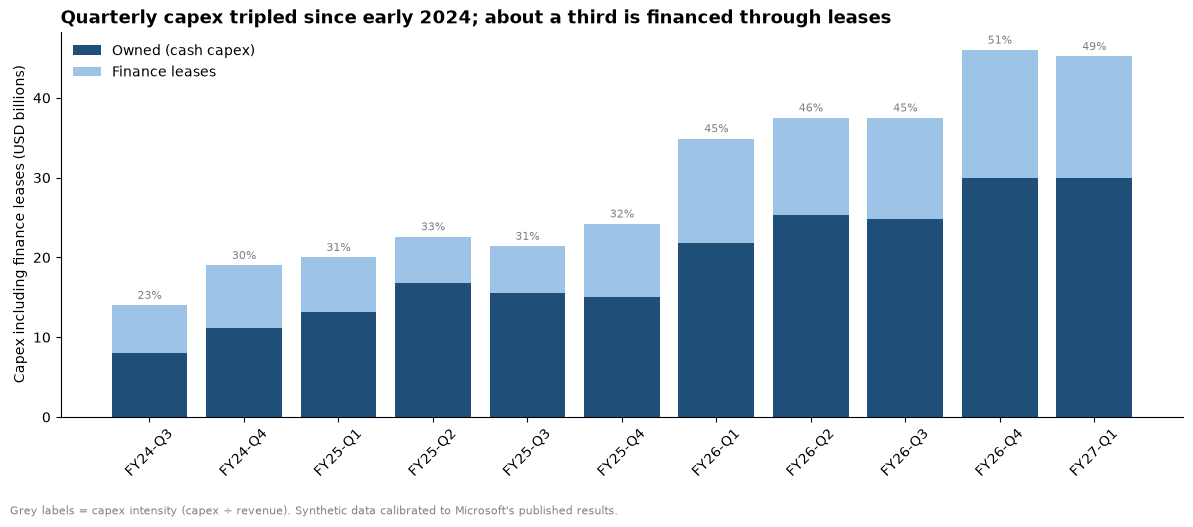

In [2]:
capex_q = con.sql("""
    SELECT fiscal_year_quarter, revenue_usd, operating_income_usd, depreciation_usd,
           capex_usd, capex_finance_lease_usd, lease_share_of_capex, free_cash_flow_usd
    FROM v_kpi_quarter
    ORDER BY quarter_start
""").df()
capex_q["capex_owned_usd"] = capex_q["capex_usd"] - capex_q["capex_finance_lease_usd"]
capex_q["capex_intensity"] = capex_q["capex_usd"] / capex_q["revenue_usd"]
capex_q["fcf_excl_leases_usd"] = capex_q["free_cash_flow_usd"] + capex_q["capex_finance_lease_usd"]

fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(capex_q))
ax.bar(x, capex_q["capex_owned_usd"] / 1e9, color="#1F4E79", label="Owned (cash capex)")
ax.bar(x, capex_q["capex_finance_lease_usd"] / 1e9, bottom=capex_q["capex_owned_usd"] / 1e9,
       color="#9DC3E6", label="Finance leases")
for i, row in capex_q.iterrows():
    ax.text(i, row["capex_usd"] / 1e9 + 0.8, f"{row['capex_intensity']:.0%}", ha="center", fontsize=8, color="grey")
ax.set_xticks(list(x))
ax.set_xticklabels(capex_q["fiscal_year_quarter"], rotation=45)
ax.set_ylabel("Capex including finance leases (USD billions)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Quarterly capex tripled since early 2024; about a third is financed through leases",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "Grey labels = capex intensity (capex ÷ revenue). "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

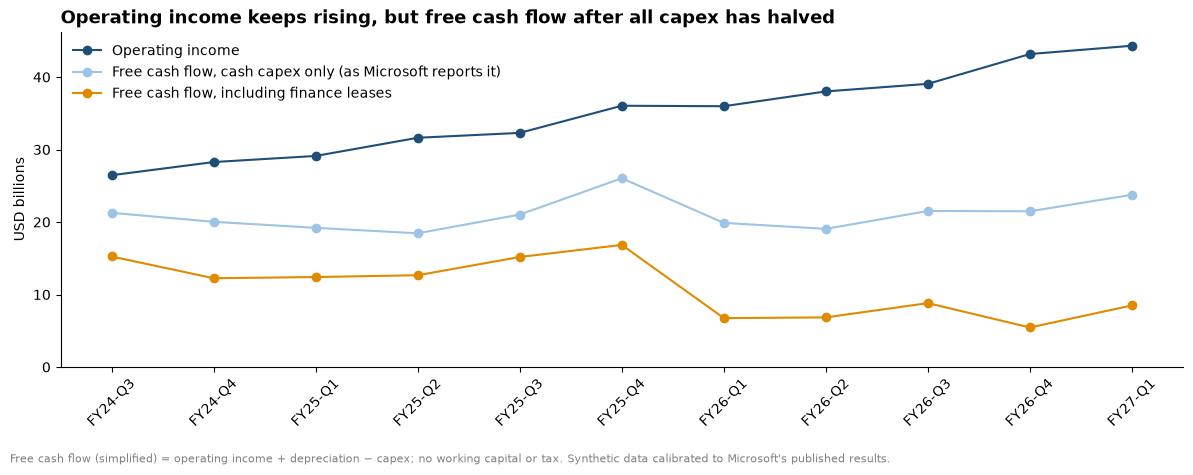

fiscal_year_quarter,revenue_usd,operating_income_usd,depreciation_usd,capex_usd,capex_finance_lease_usd,lease_share_of_capex,free_cash_flow_usd,capex_owned_usd,capex_intensity,fcf_excl_leases_usd
FY24-Q3,$61.6B,$26.5B,$2.8B,$14.0B,$6.0B,43%,$15.2B,$8.0B,23%,$21.3B
FY24-Q4,$64.3B,$28.3B,$3.0B,$19.0B,$7.8B,41%,$12.2B,$11.2B,30%,$20.0B
FY25-Q1,$65.3B,$29.1B,$3.3B,$20.0B,$6.8B,34%,$12.4B,$13.2B,31%,$19.2B
FY25-Q2,$69.2B,$31.6B,$3.6B,$22.6B,$5.8B,26%,$12.7B,$16.8B,33%,$18.4B
FY25-Q3,$69.7B,$32.3B,$4.3B,$21.4B,$5.9B,27%,$15.2B,$15.5B,31%,$21.0B
FY25-Q4,$76.2B,$36.0B,$5.0B,$24.2B,$9.2B,38%,$16.8B,$15.0B,32%,$26.0B
FY26-Q1,$77.3B,$36.0B,$5.7B,$34.9B,$13.1B,38%,$6.7B,$21.8B,45%,$19.9B
FY26-Q2,$80.9B,$38.0B,$6.3B,$37.5B,$12.2B,33%,$6.8B,$25.3B,46%,$19.1B
FY26-Q3,$82.6B,$39.1B,$7.3B,$37.5B,$12.7B,34%,$8.8B,$24.8B,45%,$21.5B
FY26-Q4,$89.7B,$43.2B,$8.3B,$46.0B,$16.0B,35%,$5.4B,$30.0B,51%,$21.5B


In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(x, capex_q["operating_income_usd"] / 1e9, marker="o", color="#1F4E79", label="Operating income")
ax.plot(x, capex_q["fcf_excl_leases_usd"] / 1e9, marker="o", color="#9DC3E6",
        label="Free cash flow, cash capex only (as Microsoft reports it)")
ax.plot(x, capex_q["free_cash_flow_usd"] / 1e9, marker="o", color="#E08A00",
        label="Free cash flow, including finance leases")
ax.set_xticks(list(x))
ax.set_xticklabels(capex_q["fiscal_year_quarter"], rotation=45)
ax.set_ylabel("USD billions")
ax.set_ylim(0, None)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Operating income keeps rising, but free cash flow after all capex has halved",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "Free cash flow (simplified) = operating income + depreciation − capex; no working capital or tax. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

capex_q.style.format({
    **{c: billions for c in capex_q.columns if c.endswith("_usd")},
    "lease_share_of_capex": "{:.0%}",
    "capex_intensity": "{:.0%}",
}).hide(axis="index")

**Findings.**
- Quarterly capex rose from $14.0B (FY24 Q3) to $45.2B (FY27 Q1); FY26 capex was $155.9B. Capex intensity went
  from 23% to 49% of revenue.
- About a third of capex (26%–43% by quarter) is datacenter buildings financed through leases.
- Operating income rose from $26.5B to $44.3B a quarter, but free cash flow including finance leases fell from
  about $17B (FY25 Q4) to about $8.5B. Excluding leases, as Microsoft reports it, free cash flow looks stable at
  about $20–24B a quarter: the lease view shows how much of the AI build-out is financed rather than paid in cash.

## 2. Capacity and utilisation

Is the new capacity being used? Installed vs used megawatts across the 34 cloud regions, and utilisation by region
over time.

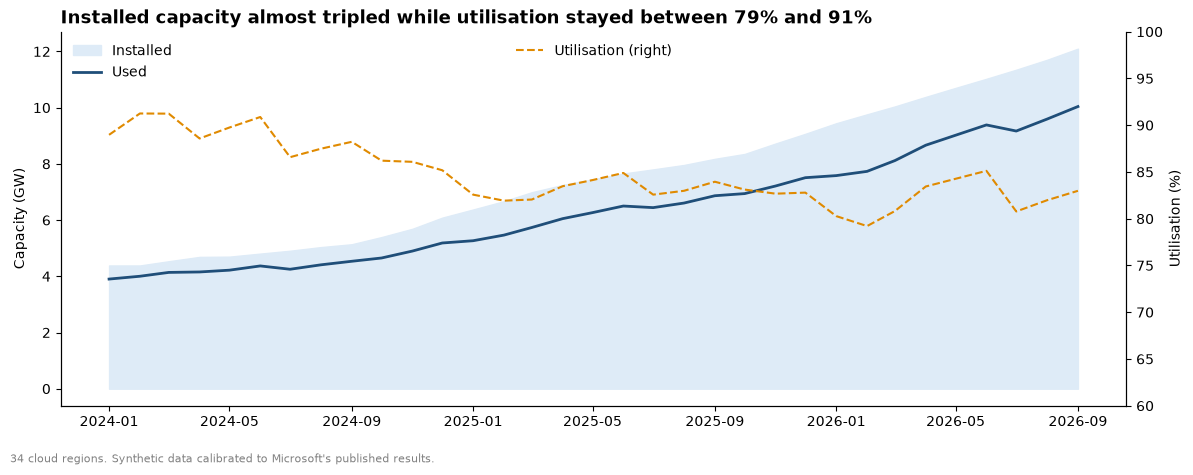

In [4]:
capacity = con.sql("""
    SELECT month_start, SUM(installed_mw) AS installed_mw, SUM(used_mw) AS used_mw,
           SUM(used_mw) / SUM(installed_mw) AS utilization
    FROM fact_datacenter
    GROUP BY month_start
    ORDER BY month_start
""").df()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(capacity["month_start"], capacity["installed_mw"] / 1000, color="#DEEBF7", label="Installed")
ax.plot(capacity["month_start"], capacity["used_mw"] / 1000, color="#1F4E79", linewidth=2, label="Used")
ax2 = ax.twinx()
ax2.plot(capacity["month_start"], capacity["utilization"] * 100, color="#E08A00", linestyle="--",
         label="Utilisation (right)")
ax2.set_ylim(60, 100)
ax2.set_ylabel("Utilisation (%)")
ax.set_ylabel("Capacity (GW)")
ax.legend(frameon=False, loc="upper left")
ax2.legend(frameon=False, loc="upper center")
for a in (ax, ax2):
    a.spines[["top"]].set_visible(False)
ax.set_title("Installed capacity almost tripled while utilisation stayed between 79% and 91%",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "34 cloud regions. Synthetic data calibrated to Microsoft's published results.",
         fontsize=8, color="grey")
plt.tight_layout()
plt.show()

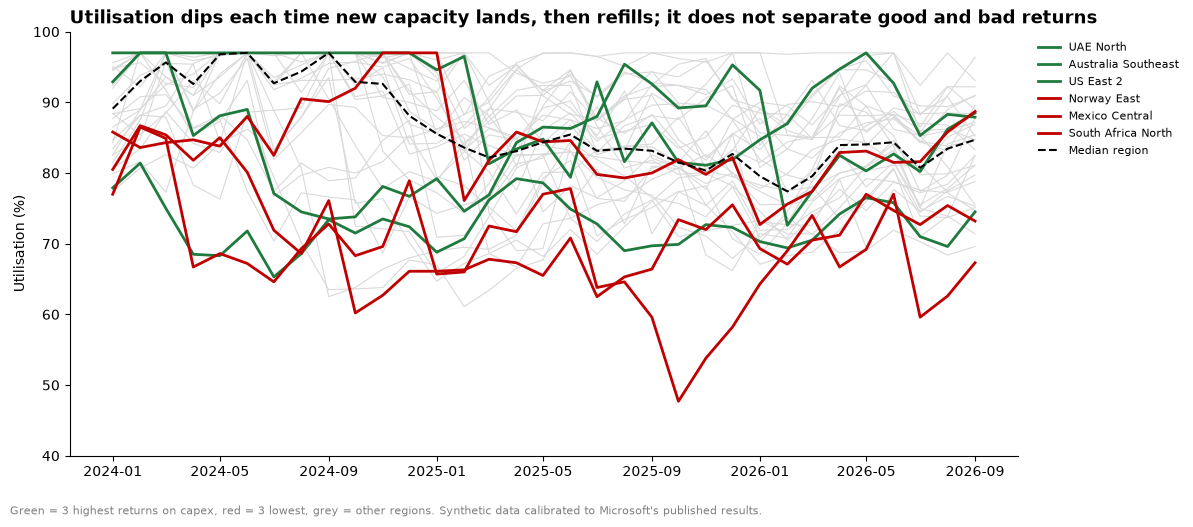

In [5]:
returns = con.sql("SELECT * FROM v_region_returns").df()
monthly = con.sql("SELECT region_code, region_name, month_start, utilization FROM v_region_month").df()

best = returns.nsmallest(3, "return_rank")["region_code"].tolist()     # 3 highest returns on capex
worst = returns.nlargest(3, "return_rank")["region_code"].tolist()     # 3 lowest

fig, ax = plt.subplots(figsize=(12, 5))
for code, g in monthly.groupby("region_code"):
    ax.plot(g["month_start"], g["utilization"] * 100, color="#D9D9D9", linewidth=0.8, zorder=1)
for codes, color in [(best, "#1F7A3E"), (worst, "#C00000")]:
    for code in codes:
        g = monthly[monthly["region_code"] == code]
        ax.plot(g["month_start"], g["utilization"] * 100, color=color, linewidth=2, zorder=2,
                label=g["region_name"].iloc[0])
median = monthly.groupby("month_start")["utilization"].median() * 100
ax.plot(median.index, median.values, color="black", linestyle="--", linewidth=1.5, label="Median region", zorder=3)
ax.set_ylabel("Utilisation (%)")
ax.set_ylim(40, 100)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Utilisation dips each time new capacity lands, then refills; it does not separate good and bad returns",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "Green = 3 highest returns on capex, red = 3 lowest, grey = other regions. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

**Findings.**
- Installed capacity grew from about 4.4 GW to 12.1 GW; utilisation stayed between 79% and 91% and is about
  83% today, so the build-out is being used.
- By region, utilisation drops each time a large block of capacity comes online and refills over the following
  months: the 6–18 month lag in the project plan.
- The best and the worst regions run at similar utilisation, so demand does not explain the difference in returns.

## 3. Return on capex by region

Two views of the capex spent from Jan 2024 to Sep 2026:
- **Realised so far:** operating income in the last 12 months minus the base year (2024), divided by capex.
  Capacity still filling (or still being built) sits in the denominator, so this view understates young regions.
- **Once capacity fills (steady state):** the cash flow each region earns per used MW today, applied to the MW
  added at 90% utilisation, minus the depreciation of the new capex, divided by capex.

Operating income is after datacenter costs, depreciation and the region's share of Azure R&D, sales and
marketing and corporate G&A (allocated by revenue share).

In [6]:
cols = ["region_name", "sales_region", "utilization_now", "mw_added", "capex_usd", "lease_share_of_capex",
        "operating_margin_ttm", "realised_return_on_capex", "return_on_capex", "payback_years",
        "useful_life_years", "npv_7_usd", "npv_9_usd", "npv_11_usd", "earns_its_cost", "verdict_changes_7_vs_11"]

returns[cols].style.format({
    **{c: billions for c in cols if c.endswith("_usd")},
    "utilization_now": "{:.0%}", "lease_share_of_capex": "{:.0%}", "operating_margin_ttm": "{:.1%}",
    "realised_return_on_capex": "{:.1%}", "return_on_capex": "{:.1%}",
    "mw_added": "{:,.0f}", "payback_years": "{:.1f}", "useful_life_years": "{:.1f}",
}).hide(axis="index")

region_name,sales_region,utilization_now,mw_added,capex_usd,lease_share_of_capex,operating_margin_ttm,realised_return_on_capex,return_on_capex,payback_years,useful_life_years,npv_7_usd,npv_9_usd,npv_11_usd,earns_its_cost,verdict_changes_7_vs_11
UAE North,EMEA,88%,64,$2.0B,19%,36.5%,7.9%,11.6%,4.1,8.8,$1.1B,$0.9B,$0.7B,True,False
Australia Southeast,APAC,88%,289,$10.0B,33%,36.6%,6.1%,10.1%,4.5,10.0,$5.5B,$4.2B,$3.0B,True,False
US East 2,Americas,74%,604,$22.4B,34%,32.7%,6.1%,8.1%,4.9,9.7,$9.3B,$6.6B,$4.3B,True,False
Japan East,APAC,87%,139,$5.2B,32%,37.5%,6.4%,8.0%,4.9,9.8,$2.1B,$1.5B,$1.0B,True,False
Germany West Central,EMEA,85%,327,$12.4B,38%,36.5%,5.8%,7.8%,5.0,9.9,$4.9B,$3.4B,$2.1B,True,False
Australia East,APAC,71%,226,$8.6B,38%,32.4%,5.2%,7.6%,5.1,10.1,$3.4B,$2.3B,$1.4B,True,False
US West 3,Americas,75%,325,$12.6B,35%,31.2%,5.3%,7.6%,5.1,10.0,$4.8B,$3.3B,$2.0B,True,False
UK West,EMEA,85%,293,$11.4B,33%,35.5%,6.9%,7.5%,5.1,10.0,$4.2B,$2.9B,$1.7B,True,False
US West 2,Americas,70%,400,$15.5B,39%,31.9%,4.1%,7.4%,5.2,10.1,$5.7B,$3.8B,$2.2B,True,False
West Europe,EMEA,81%,621,$24.3B,40%,34.0%,6.0%,7.3%,5.2,10.1,$8.7B,$5.9B,$3.4B,True,False


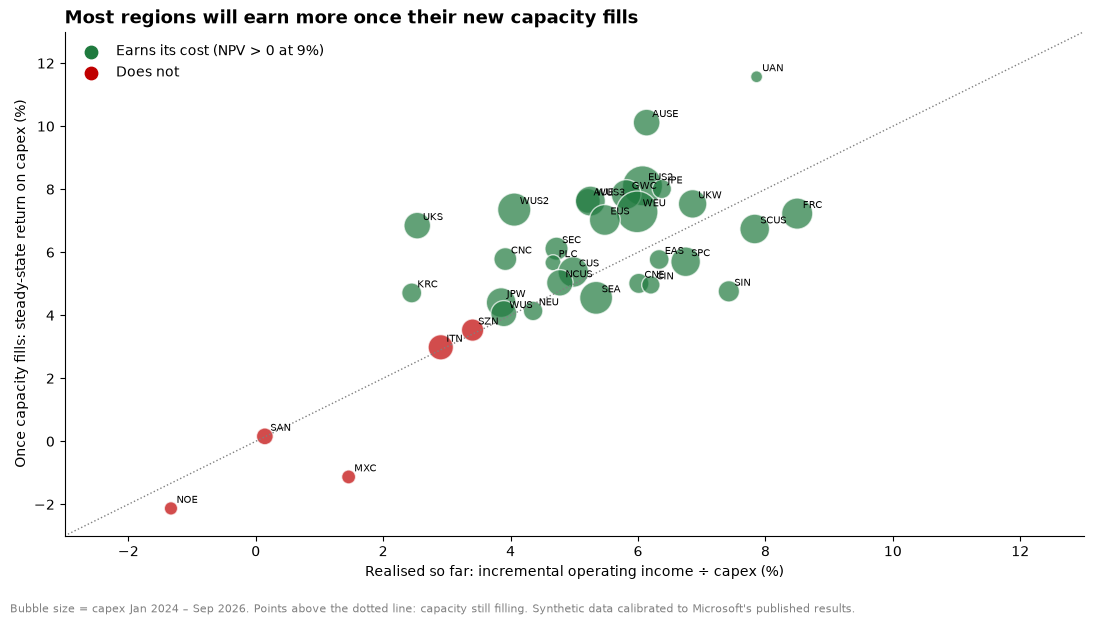

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
colors = returns["earns_its_cost"].map({True: "#1F7A3E", False: "#C00000"})
ax.scatter(returns["realised_return_on_capex"] * 100, returns["return_on_capex"] * 100,
           s=returns["capex_usd"] / returns["capex_usd"].max() * 900, c=colors, alpha=0.7, edgecolors="white")
for _, row in returns.iterrows():
    ax.annotate(row["region_code"], (row["realised_return_on_capex"] * 100, row["return_on_capex"] * 100),
                xytext=(4, 4), textcoords="offset points", fontsize=7)
lims = [-3, 13]
ax.plot(lims, lims, color="grey", linestyle=":", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Realised so far: incremental operating income ÷ capex (%)")
ax.set_ylabel("Once capacity fills: steady-state return on capex (%)")
ax.scatter([], [], c="#1F7A3E", s=80, label=f"Earns its cost (NPV > 0 at {HURDLE:.0%})")
ax.scatter([], [], c="#C00000", s=80, label="Does not")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Most regions will earn more once their new capacity fills",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Bubble size = capex Jan 2024 – Sep 2026. Points above the dotted line: capacity still filling. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

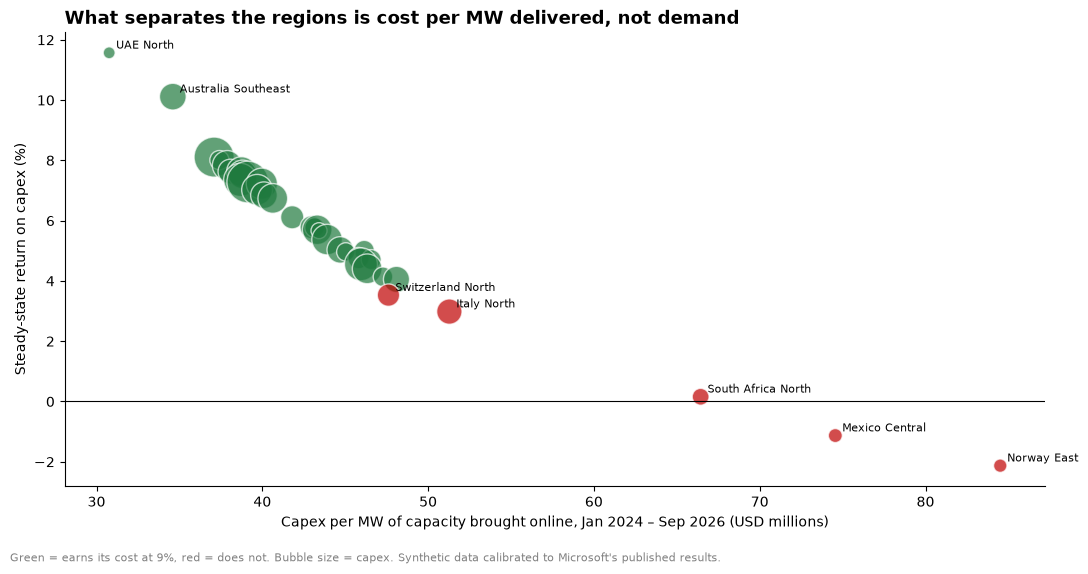

capex_per_mw_added_usd   -0.95
utilization_now           0.21
operating_margin_ttm      0.65
dtype: float64

In [8]:
returns["capex_per_mw_added_usd"] = returns["capex_usd"] / returns["mw_added"]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(returns["capex_per_mw_added_usd"] / 1e6, returns["return_on_capex"] * 100,
           s=returns["capex_usd"] / returns["capex_usd"].max() * 900,
           c=returns["earns_its_cost"].map({True: "#1F7A3E", False: "#C00000"}), alpha=0.7, edgecolors="white")
for _, row in returns.iterrows():
    if not row["earns_its_cost"] or row["return_on_capex"] > 0.09:
        ax.annotate(row["region_name"], (row["capex_per_mw_added_usd"] / 1e6, row["return_on_capex"] * 100),
                    xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Capex per MW of capacity brought online, Jan 2024 – Sep 2026 (USD millions)")
ax.set_ylabel("Steady-state return on capex (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("What separates the regions is cost per MW delivered, not demand",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Green = earns its cost at 9%, red = does not. Bubble size = capex. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

# How strongly each driver moves with the return (correlation, -1 to 1)
returns[["capex_per_mw_added_usd", "utilization_now", "operating_margin_ttm"]].corrwith(returns["return_on_capex"]).round(2)

**Findings.**
- Once capacity fills, returns range from −2% (Norway East) to 12% (UAE North). The realised returns so far are
  lower for most regions, because part of the capex is for capacity that is still filling or not yet online.
- The return is driven by **cost per MW delivered** (correlation −0.95), not by utilisation (+0.21). The best
  regions brought capacity online at about $31–40M per MW; the weakest at $48–85M per MW, because of cost overruns
  and spend on capacity that is not yet online.

## 4. Payback and NPV against the 9% hurdle rate

Capex rule: a region earns its cost when its **NPV at 9% is positive** and its **payback is within the assets'
useful life** (buildings 15 years, servers and GPUs 6, network 10, weighted by each region's capex). The black
line on each bar shows the NPV range from 11% (left end) to 7% (right end).

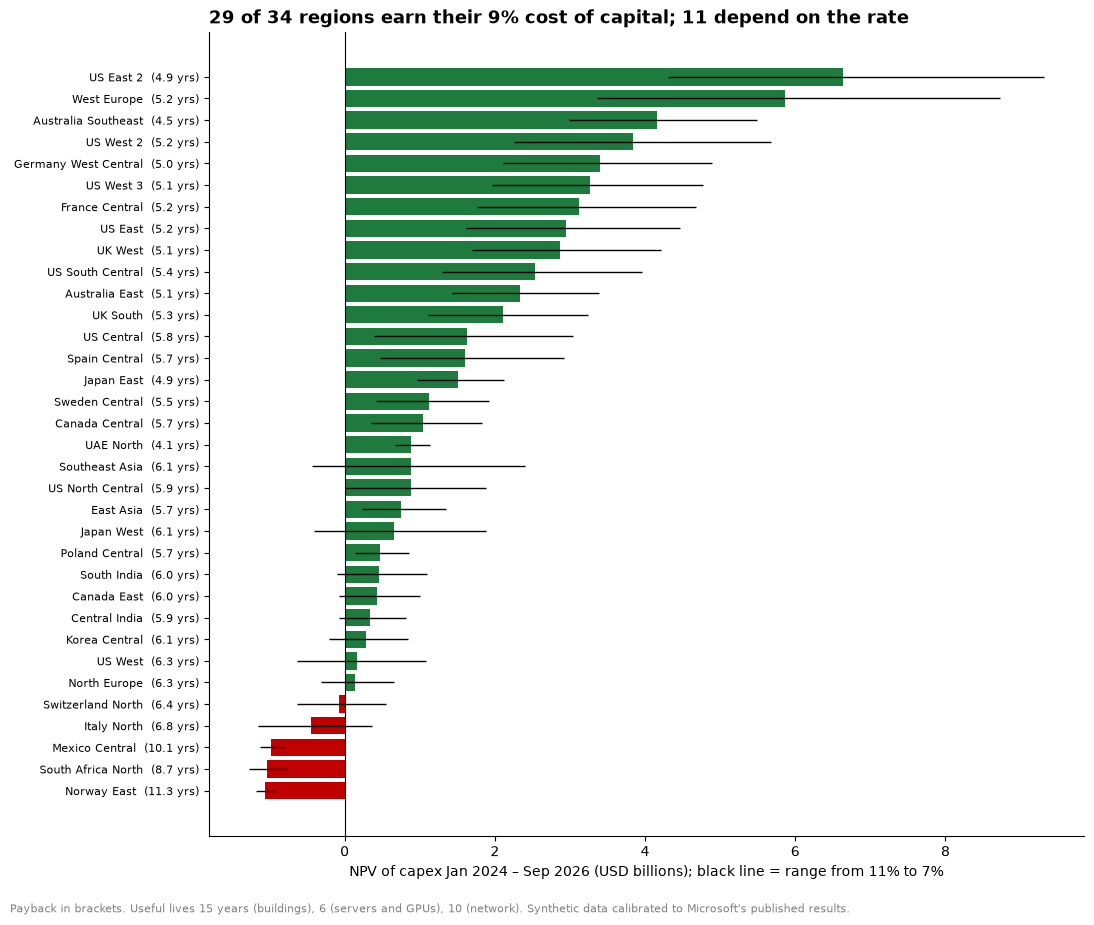

Total NPV at 9%: $52.7B on $322.3B of capex; median payback 5.7 years


In [9]:
npv = returns.sort_values("npv_9_usd")

fig, ax = plt.subplots(figsize=(11, 9))
y = range(len(npv))
ax.barh(y, npv["npv_9_usd"] / 1e9, color=npv["earns_its_cost"].map({True: "#1F7A3E", False: "#C00000"}))
ax.hlines(y, npv["npv_11_usd"] / 1e9, npv["npv_7_usd"] / 1e9, color="black", linewidth=1)
ax.set_yticks(list(y))
ax.set_yticklabels(npv["region_name"] + "  (" + npv["payback_years"].map("{:.1f}".format) + " yrs)", fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("NPV of capex Jan 2024 – Sep 2026 (USD billions); black line = range from 11% to 7%")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"{int(returns['earns_its_cost'].sum())} of {len(returns)} regions earn their {HURDLE:.0%} cost of capital; "
             f"{int(returns['verdict_changes_7_vs_11'].sum())} depend on the rate",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.02, "Payback in brackets. Useful lives 15 years (buildings), 6 (servers and GPUs), 10 (network). "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

print(f"Total NPV at {HURDLE:.0%}: {billions(returns['npv_9_usd'].sum())} on {billions(returns['capex_usd'].sum())} of capex; "
      f"median payback {returns['payback_years'].median():.1f} years")

**Findings.**
- **29 of 34 regions earn their 9% cost of capital.** Together the capex of $322B has an NPV of about +$53B,
  with a median payback of 5.7 years.
- **5 regions do not:** Norway East, Mexico Central, South Africa North, Italy North and Switzerland North.
  Their paybacks (6.4–11.3 years) are close to or beyond the assets' useful life.
- **11 regions change verdict between 7% and 11%**, so for those the cost-of-capital assumption decides the answer.

## 5. Capex shift

Value of moving one year of capex from the regions that do not earn their cost to the five regions with the
highest returns, once the capacity fills:
added operating income = capex shifted × (return of the "to" regions − return of the "from" regions).

In [10]:
shift_from = returns[~returns["earns_its_cost"]]
shift_to = returns.nsmallest(5, "return_rank")

ttm_capex = con.sql("""
    SELECT region_code, SUM(capex_usd) AS capex_ttm_usd
    FROM v_region_month
    WHERE month_start >= (SELECT ttm_start FROM v_params)
    GROUP BY region_code
""").df()

shift_amount = ttm_capex.loc[ttm_capex["region_code"].isin(shift_from["region_code"]), "capex_ttm_usd"].sum()
return_from = (shift_from["return_on_capex"] * shift_from["capex_usd"]).sum() / shift_from["capex_usd"].sum()
return_to = (shift_to["return_on_capex"] * shift_to["capex_usd"]).sum() / shift_to["capex_usd"].sum()
added_oi = shift_amount * (return_to - return_from)

shift_summary = pd.DataFrame({
    "item": ["Shift capex from (NPV < 0 at 9%)", "Shift capex to (top 5 returns)",
             "Capex to shift (last 12 months of capex in the 'from' regions)",
             "Capex-weighted return, 'from' regions", "Capex-weighted return, 'to' regions",
             "Added operating income a year, once capacity fills"],
    "value": [", ".join(shift_from["region_name"]), ", ".join(shift_to["region_name"]), billions(shift_amount),
              f"{return_from:.1%}", f"{return_to:.1%}", billions(added_oi)],
})
shift_summary.style.hide(axis="index")

item,value
Shift capex from (NPV < 0 at 9%),"Switzerland North, Italy North, South Africa North, Mexico Central, Norway East"
Shift capex to (top 5 returns),"UAE North, Australia Southeast, US East 2, Japan East, Germany West Central"
Capex to shift (last 12 months of capex in the 'from' regions),$14.2B
"Capex-weighted return, 'from' regions",1.7%
"Capex-weighted return, 'to' regions",8.6%
"Added operating income a year, once capacity fills",$1.0B


**Finding.** Moving the last 12 months of capex in the five regions that do not earn their cost (**$14.2B**) to
the five highest-return regions (UAE North, Australia Southeast, US East 2, Japan East, Germany West Central)
lifts the return on that capex from 1.7% to 8.6% and adds about **$1.0B of operating income a year** once the
capacity fills.

## Summary
- Capex tripled to $45B a quarter, a third of it through finance leases; free cash flow including leases halved.
- New capacity fills up (utilisation 79%–91%), and 29 of 34 regions earn their 9% cost of capital.
- Returns depend on **cost per MW delivered**: the five weakest regions spend $48–85M per MW against $31–40M in
  the best ones.
- **Recommendation for the executive summary:** shift about $14B of FY27 datacenter capex from Norway East,
  Mexico Central, South Africa North, Italy North and Switzerland North to the five highest-return regions, adding
  about $1B of operating income a year; review the cost overruns in the weak regions before approving new builds there.
- **Next:** `05_budget_variance.ipynb`: why actual operating income differs from plan.

In [11]:
con.close()   # releases data/finance.duckdb so the next notebook can open it